# Lead-acid plate defect classifier: surface error / crack / bend

**Folder layout** (one level above this notebook):

```
data/good/   data/surface_error/   data/crack/   data/bend/
```

**Naming rules**
- Every file starts with its plate ID and an underscore: `plate03_12.jpg`
- Generated (Gemini) images carry the ID of their SOURCE plate and the word `synthetic`: `plate03_synthetic_crack_2.jpg`

**Why the rules matter:** the notebook splits by plate (never by photo) so the model is always tested on plates it never saw in training, and generated images are used for training only, never for testing. The numbers in the paper come from the cross-validation section, not from the final saved model.

In [1]:
import os, copy, random
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import classification_report, confusion_matrix, f1_score

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


## 1. Settings

In [2]:
CLASSES = ["good", "surface_error", "crack", "bend"]
DATA_DIR = Path("..") / "data"
IMG_SIZE = 224
BATCH_SIZE = 8
EPOCHS = 15
LR = 1e-4

## 2. Load images, classes, plate IDs and the synthetic flag
The class comes from the folder name, the plate from the filename prefix. Check the printout before going further: every plate should show up, and the real counts per class tell you how much each class can really be trusted.

In [3]:
paths, labels = [], []
for ci, c in enumerate(CLASSES):
    folder = DATA_DIR / c
    if not folder.exists():
        print("Missing folder:", folder)
        continue
    for p in sorted(folder.glob("*.*")):
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            paths.append(str(p)); labels.append(ci)
assert len(paths) > 0, "No images found - check the data folders."

labels = np.array(labels)
names = [os.path.basename(p) for p in paths]
groups = np.array([n.split("_")[0] for n in names])
is_synth = np.array(["synthetic" in n for n in names])

no_prefix = [n for n in names if "_" not in n]
if no_prefix:
    print("These files have no plateID_ prefix and need renaming:", no_prefix)

print("Class counts (real / synthetic):")
for ci, c in enumerate(CLASSES):
    print("  %-14s %3d / %3d" % (c, ((labels == ci) & ~is_synth).sum(), ((labels == ci) & is_synth).sum()))

plates = sorted(set(groups))
print("Plates (%d): %s" % (len(plates), plates))
for g in plates:
    m = (groups == g) & ~is_synth
    print("  ", g, {c: int(((labels == ci) & m).sum()) for ci, c in enumerate(CLASSES)})

These files have no plateID_ prefix and need renaming: ['1.png', '10.jpg', '11.jpg', '12.jpg', '13.jpg', '14.jpg', '2.png', '3.jpg', '4.jpg', '5.jpg', '6.jpg', '7.jpg', '8.jpg', '9.jpg', '1.jpg', '10.jpg', '11.jpg', '12.jpg', '13.jpg', '14.jpg', '15.jpg', '16.jpg', '17.jpg', '18.jpg', '19.jpg', '2.jpg', '20.jpg', '21.jpg', '22.jpg', '23.jpg', '24.jpg', '3.jpg', '4.jpg', '5.jpg', '6.jpg', '7.jpg', '8.jpg', '9.jpg', '12.jpg', '13.jpg', '14.jpg', '15.jpg', '16.jpg', '17.jpg', '18.jpg', '19.jpg', '20.jpg', '21.jpg', '22.jpg', '23.jpg', '24.jpg', '25.jpg', '26.png', '27.jpg', '28.jpg']
Class counts (real / synthetic):
  good            14 /   0
  surface_error   24 /   0
  crack           27 /   0
  bend            15 /   0
Plates (45): [np.str_('01'), np.str_('02'), np.str_('03'), np.str_('04'), np.str_('05'), np.str_('06'), np.str_('07'), np.str_('08'), np.str_('09'), np.str_('1.jpg'), np.str_('1.png'), np.str_('10'), np.str_('10.jpg'), np.str_('11'), np.str_('11.jpg'), np.str_('12'), np.

## 3. Look at a few real examples per class
A quick check that each folder really contains what its name says. Mislabeled images are the cheapest error to fix and the most damaging to leave in.

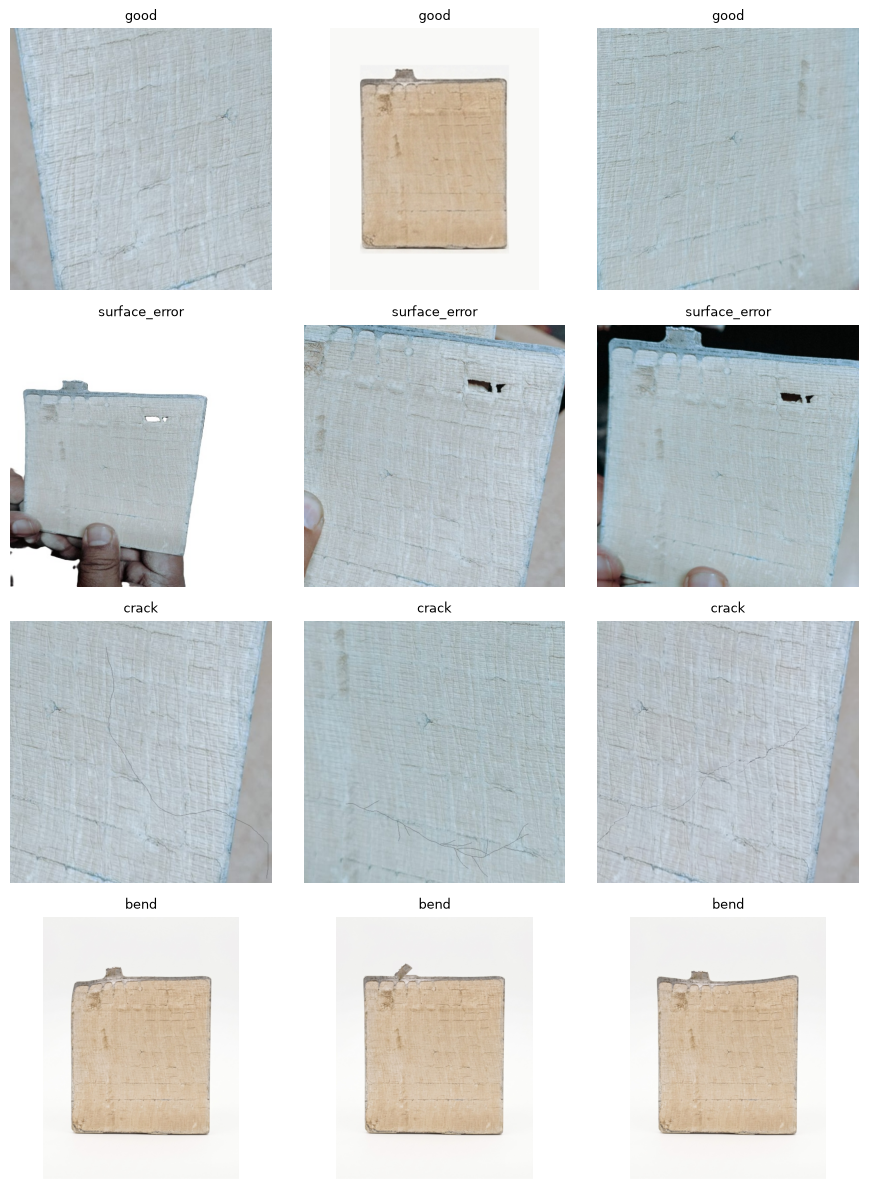

In [4]:
fig, axes = plt.subplots(len(CLASSES), 3, figsize=(9, 3 * len(CLASSES)))
for ci, c in enumerate(CLASSES):
    idx = [i for i in range(len(paths)) if labels[i] == ci and not is_synth[i]]
    picks = random.sample(idx, min(3, len(idx)))
    for j in range(3):
        ax = axes[ci][j]
        ax.axis("off")
        if j < len(picks):
            ax.imshow(Image.open(paths[picks[j]]).convert("RGB"))
            ax.set_title(c, fontsize=9)
plt.tight_layout()
plt.show()

## 4. Dataset, augmentation, model, training step

- **Augmentation** (training only): small rotations and brightness changes, so the model cannot rely on exact camera angle or lighting. Vertical flips are left out because a real lug always sits at the top.
- **Partial fine-tuning:** only the last ResNet block and the new output layer learn. With this little data, retraining everything would memorize the photos.
- **Frozen batch-norm:** the frozen layers keep ImageNet statistics instead of drifting toward a tiny dataset.
- **Class weights:** rare classes count more in the loss, so the model cannot score well by ignoring them.

In [5]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(20),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.25, contrast=0.25),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class PlateDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.transform = paths, labels, transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        return self.transform(img), int(self.labels[idx])

def build_model():
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    for name, param in model.named_parameters():
        param.requires_grad = name.startswith("layer4") or name.startswith("fc")
    model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
    return model.to(device)

def set_train_mode(model):
    model.train()
    for name, m in model.named_modules():
        if isinstance(m, nn.BatchNorm2d) and not name.startswith("layer4"):
            m.eval()

def class_weights(train_labels):
    counts = np.bincount(train_labels, minlength=len(CLASSES))
    w = len(train_labels) / (len(CLASSES) * np.maximum(counts, 1))
    return torch.tensor(w, dtype=torch.float32).to(device)

def run_epoch(model, loader, optimizer, criterion, train=True):
    if train:
        set_train_mode(model)
    else:
        model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if train:
                optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            if train:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

## 5. Leave-one-plate-out cross-validation
Each round holds out every photo of one plate, trains a fresh model on the rest, and tests on the held-out plate's REAL photos. Generated images are in training only when `use_synth=True`. A fresh model is built each round so nothing leaks between rounds.

In [6]:
def run_cv(use_synth):
    all_true, all_pred, fold_summary = [], [], []
    for train_idx, test_idx in LeaveOneGroupOut().split(paths, labels, groups):
        if not use_synth:
            train_idx = train_idx[~is_synth[train_idx]]
        test_idx = test_idx[~is_synth[test_idx]]
        if len(test_idx) == 0:
            continue
        held_out = groups[test_idx[0]]
        assert held_out not in set(groups[train_idx]), "plate leakage"

        train_labels = labels[train_idx]
        train_loader = DataLoader(
            PlateDataset([paths[i] for i in train_idx], train_labels, train_transform),
            batch_size=BATCH_SIZE, shuffle=True)
        test_loader = DataLoader(
            PlateDataset([paths[i] for i in test_idx], labels[test_idx], eval_transform),
            batch_size=BATCH_SIZE, shuffle=False)

        model = build_model()
        optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LR)
        criterion = nn.CrossEntropyLoss(weight=class_weights(train_labels))
        for epoch in range(EPOCHS):
            run_epoch(model, train_loader, optimizer, criterion, train=True)

        model.eval()
        preds = []
        with torch.no_grad():
            for x, y in test_loader:
                preds.extend(model(x.to(device)).argmax(1).cpu().tolist())
        true = labels[test_idx].tolist()
        all_true.extend(true)
        all_pred.extend(preds)
        acc = float(np.mean(np.array(preds) == np.array(true)))
        fold_summary.append((held_out, len(true), acc))
        print("held out %s (%d photos): accuracy %.2f" % (held_out, len(true), acc))
    return all_true, all_pred, fold_summary


def show_results(all_true, all_pred, fold_summary, title):
    k = list(range(len(CLASSES)))
    accs = [a for _, _, a in fold_summary]
    print("=== %s ===" % title)
    print("Per-plate accuracy: mean %.2f +/- %.2f over %d plates" % (np.mean(accs), np.std(accs), len(accs)))
    print(classification_report(all_true, all_pred, labels=k, target_names=CLASSES, zero_division=0))
    cm = confusion_matrix(all_true, all_pred, labels=k)
    print(cm)
    fig, ax = plt.subplots(figsize=(4.8, 4.2))
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(k); ax.set_xticklabels(CLASSES, rotation=45, ha="right")
    ax.set_yticks(k); ax.set_yticklabels(CLASSES)
    ax.set_xlabel("predicted"); ax.set_ylabel("actual"); ax.set_title(title)
    for i in k:
        for j in k:
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.tight_layout()
    plt.show()
    return f1_score(all_true, all_pred, labels=k, average="macro", zero_division=0)

## 6. Run it (with generated images in training)
This is the number to report. It is slow on a CPU, because it trains one model per plate.

held out 01 (2 photos): accuracy 0.50
held out 02 (2 photos): accuracy 0.50
held out 03 (2 photos): accuracy 0.50
held out 04 (2 photos): accuracy 0.50
held out 05 (2 photos): accuracy 0.50
held out 06 (2 photos): accuracy 1.00
held out 07 (2 photos): accuracy 0.50
held out 08 (2 photos): accuracy 0.50
held out 09 (2 photos): accuracy 0.50
held out 1.jpg (1 photos): accuracy 1.00
held out 1.png (1 photos): accuracy 0.00
held out 10 (2 photos): accuracy 0.50
held out 10.jpg (2 photos): accuracy 1.00
held out 11 (1 photos): accuracy 1.00
held out 11.jpg (2 photos): accuracy 1.00
held out 12 (1 photos): accuracy 1.00
held out 12.jpg (3 photos): accuracy 1.00
held out 13 (1 photos): accuracy 1.00
held out 13.jpg (3 photos): accuracy 1.00
held out 14 (1 photos): accuracy 1.00
held out 14.jpg (3 photos): accuracy 1.00
held out 15 (1 photos): accuracy 1.00
held out 15.jpg (2 photos): accuracy 1.00
held out 16.jpg (2 photos): accuracy 1.00
held out 17.jpg (2 photos): accuracy 1.00
held out 18.

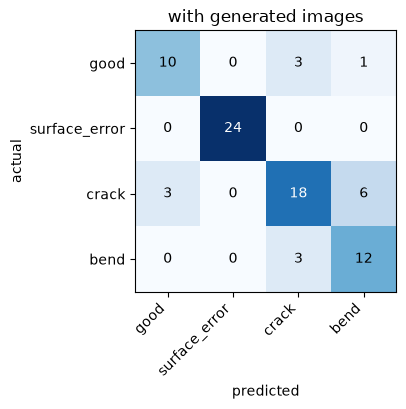

In [7]:
assert len(set(groups)) >= 2, "Need at least 2 plates for leave-one-plate-out."
res_with = run_cv(use_synth=True)
f1_with = show_results(*res_with, "with generated images")

## 7. Ablation: the same run without generated images(Skip if no generated images)
If the macro-F1 is not clearly better with them, say so in the paper and drop them. Skip this cell if time is short.

held out 01 (2 photos): accuracy 0.50
held out 02 (2 photos): accuracy 0.50
held out 03 (2 photos): accuracy 0.50
held out 04 (2 photos): accuracy 0.50
held out 05 (2 photos): accuracy 0.50
held out 06 (2 photos): accuracy 0.50
held out 07 (2 photos): accuracy 0.50
held out 08 (2 photos): accuracy 1.00
held out 09 (2 photos): accuracy 0.50
held out 1.jpg (1 photos): accuracy 1.00
held out 1.png (1 photos): accuracy 0.00
held out 10 (2 photos): accuracy 0.50
held out 10.jpg (2 photos): accuracy 1.00
held out 11 (1 photos): accuracy 1.00
held out 11.jpg (2 photos): accuracy 1.00
held out 12 (1 photos): accuracy 1.00
held out 12.jpg (3 photos): accuracy 1.00
held out 13 (1 photos): accuracy 1.00
held out 13.jpg (3 photos): accuracy 0.67
held out 14 (1 photos): accuracy 0.00
held out 14.jpg (3 photos): accuracy 1.00
held out 15 (1 photos): accuracy 1.00
held out 15.jpg (2 photos): accuracy 1.00
held out 16.jpg (2 photos): accuracy 1.00
held out 17.jpg (2 photos): accuracy 1.00
held out 18.

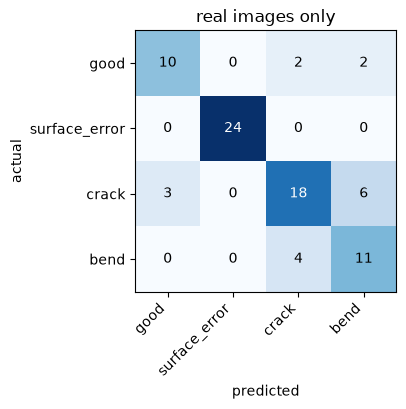

macro-F1 with generated: 0.788   real only: 0.773


In [8]:
res_without = run_cv(use_synth=False)
f1_without = show_results(*res_without, "real images only")
print("macro-F1 with generated: %.3f   real only: %.3f" % (f1_with, f1_without))

## 8. Train the model you will deploy, and save it
The cross-validation models were throwaways, because each saw only some of the plates. This one uses everything. Its own training accuracy is not a result to report.

In [9]:
final_loader = DataLoader(PlateDataset(paths, labels, train_transform),
                          batch_size=BATCH_SIZE, shuffle=True)
model = build_model()
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LR)
criterion = nn.CrossEntropyLoss(weight=class_weights(labels))
for epoch in range(EPOCHS):
    loss, acc = run_epoch(model, final_loader, optimizer, criterion, train=True)
    print("epoch %02d  loss %.3f  train_acc %.2f" % (epoch + 1, loss, acc))

torch.save({"state_dict": model.state_dict(), "classes": CLASSES}, "plate_classifier.pt")
print("Saved plate_classifier.pt in the notebooks folder. Copy it next to app.py.")

epoch 01  loss 1.263  train_acc 0.36
epoch 02  loss 0.747  train_acc 0.70
epoch 03  loss 0.611  train_acc 0.78
epoch 04  loss 0.693  train_acc 0.68
epoch 05  loss 0.631  train_acc 0.69
epoch 06  loss 0.648  train_acc 0.78
epoch 07  loss 0.604  train_acc 0.74
epoch 08  loss 0.508  train_acc 0.80
epoch 09  loss 0.503  train_acc 0.79
epoch 10  loss 0.470  train_acc 0.82
epoch 11  loss 0.543  train_acc 0.78
epoch 12  loss 0.458  train_acc 0.81
epoch 13  loss 0.421  train_acc 0.84
epoch 14  loss 0.408  train_acc 0.85
epoch 15  loss 0.430  train_acc 0.84
Saved plate_classifier.pt in the notebooks folder. Copy it next to app.py.


## 9. Quick single-image check

In [10]:
def predict_image(path):
    img = Image.open(path).convert("RGB")
    x = eval_transform(img).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        p = torch.softmax(model(x), dim=1)[0].cpu().numpy()
    return CLASSES[int(p.argmax())], {c: round(float(v), 3) for c, v in zip(CLASSES, p)}

print(predict_image(paths[0]))

('good', {'good': 0.585, 'surface_error': 0.01, 'crack': 0.308, 'bend': 0.098})
